In [1]:
import sys, json
sys.path.append("../src")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from config import PROCESSED_DIR, FIGURES_DIR

sns.set_theme(style="whitegrid")
feat = pd.read_csv(PROCESSED_DIR / "features.csv", parse_dates=["date"],
                   dtype={"season": str}, index_col="match_id")
FEATURES = json.loads((PROCESSED_DIR / "feature_columns.json").read_text())
print(feat.shape, len(FEATURES), "variables")
feat[FEATURES].describe().round(2).T

(25775, 34) 26 variables


,count,mean,std,min,25%,50%,75%,max
home_gf_avg5,25775.0,1.39,0.68,0.0,0.8,1.2,1.8,6.20
home_ga_avg5,25775.0,1.41,0.62,0.0,1.0,1.4,1.8,4.60
home_points_avg5,25775.0,1.36,0.69,0.0,0.8,1.4,1.8,3.00
home_win_avg5,25775.0,0.37,0.25,0.0,0.2,0.4,0.6,1.00
home_draw_avg5,25775.0,0.25,0.20,0.0,0.2,0.2,0.4,1.00
home_gd_avg5,25775.0,-0.02,1.02,-4.2,-0.6,0.0,0.6,5.80
home_gf_venue5,25775.0,1.56,0.74,0.0,1.0,1.4,2.0,5.80
home_ga_venue5,25775.0,1.24,0.58,0.0,0.8,1.2,1.6,4.67
home_points_venue5,25775.0,1.58,0.70,0.0,1.0,1.6,2.0,3.00
home_rest_days,25775.0,7.56,3.19,2.0,6.0,7.0,8.0,14.00


In [2]:
raw = pd.read_csv(PROCESSED_DIR / "matches_clean.csv", parse_dates=["date"],
                  dtype={"season": str})   # même ordre que dans build_features

def last_matches(team, mid, n=5):
    past = raw.loc[:mid - 1]
    g = past[(past.home_team == team) | (past.away_team == team)].tail(n)
    return np.where(g.home_team == team, g.home_goals, g.away_goals).mean()

def last_home(team, mid, n=5):
    past = raw.loc[:mid - 1]
    return past[past.home_team == team].tail(n).home_goals.mean()

errors = 0
for mid in feat.sample(300, random_state=1).index:
    r, f = raw.loc[mid], feat.loc[mid]
    ok = (np.isclose(last_matches(r.home_team, mid), f["home_gf_avg5"])
          and np.isclose(last_home(r.home_team, mid), f["home_gf_venue5"])
          and np.isclose(last_matches(r.away_team, mid), f["away_gf_avg5"]))
    errors += (not ok)

print(f"Matchs testés : 300 | écarts détectés : {errors}")

Matchs testés : 300 | écarts détectés : 0


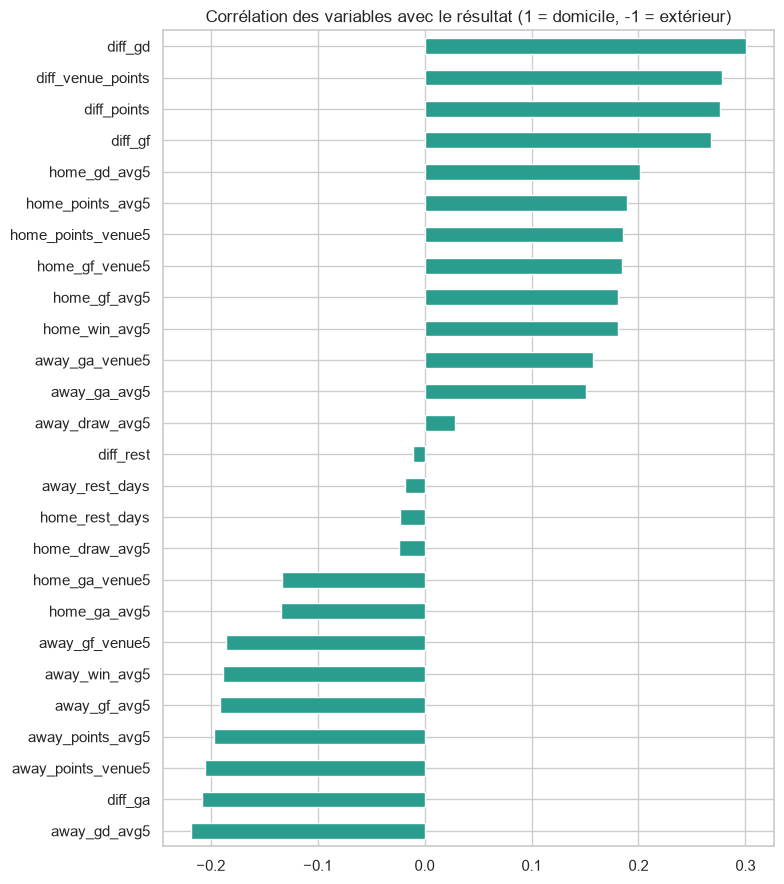

In [3]:
feat["target"] = feat["result"].map({"H": 1, "D": 0, "A": -1})
corr = feat[FEATURES + ["target"]].corr()["target"].drop("target").sort_values()

plt.figure(figsize=(8, 9))
corr.plot(kind="barh", color="#2a9d8f")
plt.title("Corrélation des variables avec le résultat (1 = domicile, -1 = extérieur)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_correlation.png", dpi=150)
plt.show()

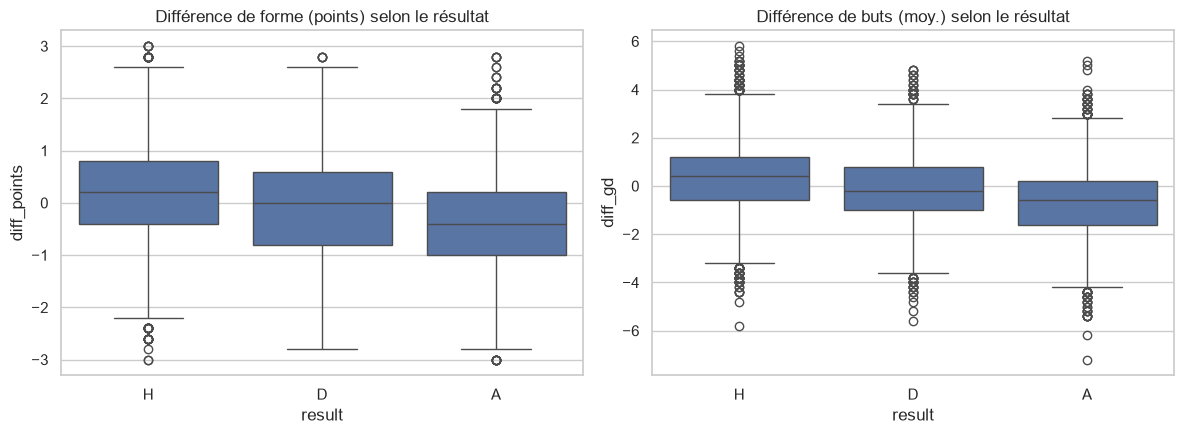

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order = ["H", "D", "A"]
sns.boxplot(data=feat, x="result", y="diff_points", order=order, ax=axes[0])
axes[0].set_title("Différence de forme (points) selon le résultat")
sns.boxplot(data=feat, x="result", y="diff_gd", order=order, ax=axes[1])
axes[1].set_title("Différence de buts (moy.) selon le résultat")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "features_by_result.png", dpi=150)
plt.show()

In [5]:
from IPython.display import Markdown, display
from config import ROOT

# --- Calculs ---
top = corr.reindex(corr.abs().sort_values(ascending=False).index)
t1, t2, t3 = top.index[:3]
c1, c2, c3 = top.iloc[:3]
max_abs = top.abs().iloc[0]
median_abs = top.abs().median()

if max_abs < 0.2:
    force = "faibles"
elif max_abs < 0.4:
    force = "modestes"
else:
    force = "relativement fortes"

if errors == 0:
    leak_txt = ("**0 écart** sur 300 matchs tirés au hasard : les moyennes recalculées à la main "
                "sur les matchs précédents sont identiques à celles du fichier. "
                "Aucune information du match à prédire (ni future) n'est utilisée.")
else:
    leak_txt = (f"**{errors} écart(s) détecté(s)** sur 300 matchs testés : les variables doivent "
                "être vérifiées avant toute modélisation (risque de fuite d'information).")

texte = f"""## Conclusions de l'ingénierie des variables

- **Variables les plus corrélées au résultat** : `{t1}` ({c1:+.2f}), `{t2}` ({c2:+.2f}) et `{t3}` ({c3:+.2f}). Les différences entre l'équipe à domicile et l'équipe à l'extérieur (forme, buts, différence de buts) sont les plus informatives.
- **Corrélations {force}** : la plus forte atteint {max_abs:.2f} en valeur absolue et la médiane des variables est de {median_abs:.2f}. Aucune variable ne détermine à elle seule l'issue d'un match, ce qui est cohérent avec la part de hasard propre au football.
- **Test anti-fuite** : {leak_txt}
- **Conséquence pour la suite** : un modèle ne pourra améliorer la référence que modestement. Il faudra le juger sur la log-loss et sur des données chronologiquement postérieures à l'entraînement.
"""

display(Markdown(texte))
(ROOT / "reports" / "feature_engineering_notes.md").write_text(texte, encoding="utf-8")

## Conclusions de l'ingénierie des variables

- **Variables les plus corrélées au résultat** : `diff_gd` (+0.30), `diff_venue_points` (+0.28) et `diff_points` (+0.28). Les différences entre l'équipe à domicile et l'équipe à l'extérieur (forme, buts, différence de buts) sont les plus informatives.
- **Corrélations modestes** : la plus forte atteint 0.30 en valeur absolue et la médiane des variables est de 0.19. Aucune variable ne détermine à elle seule l'issue d'un match, ce qui est cohérent avec la part de hasard propre au football.
- **Test anti-fuite** : **0 écart** sur 300 matchs tirés au hasard : les moyennes recalculées à la main sur les matchs précédents sont identiques à celles du fichier. Aucune information du match à prédire (ni future) n'est utilisée.
- **Conséquence pour la suite** : un modèle ne pourra améliorer la référence que modestement. Il faudra le juger sur la log-loss et sur des données chronologiquement postérieures à l'entraînement.


969